In [ ]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_validate,GridSearchCV, cross_val_score
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn import metrics

from sklearn.metrics import roc_curve, classification_report, confusion_matrix
import eli5
from eli5.sklearn import PermutationImportance
from IPython.display import display
from IPython.core.display import HTML

import joblib



In [2]:
df= pd.read_csv(r"D:\ML Projects\heart disease detection (classification)\heart.csv",encoding='latin-1')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


EDA

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [4]:
print(f"Shape : {df.shape}\n"
      f"size: {df.size}\n"
      f"Dimension : {df.ndim}")

Shape : (1025, 14)
size: 14350
Dimension : 2


In [5]:
# check missing 
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [6]:
# check duplicate
print("Total duplicate: ",df.duplicated().sum())
duplicate= df[df.duplicated(keep=False)]
print("All duplicate rows:",duplicate.shape)
duplicate.head(10)

Total duplicate:  723
All duplicate rows: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
5,58,0,0,100,248,0,0,122,0,1.0,1,0,2,1
6,58,1,0,114,318,0,2,140,0,4.4,0,3,1,0
7,55,1,0,160,289,0,0,145,1,0.8,1,1,3,0
8,46,1,0,120,249,0,0,144,0,0.8,2,0,3,0
9,54,1,0,122,286,0,0,116,1,3.2,1,2,2,0


In [7]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [8]:
df.nunique()

age          41
sex           2
cp            4
trestbps     49
chol        152
fbs           2
restecg       3
thalach      91
exang         2
oldpeak      40
slope         3
ca            5
thal          4
target        2
dtype: int64

In [9]:
cat_col= [col for col in df.columns if df[col].dtype=="object" or df[col].nunique()<=10]
num_col= [col for col in df.columns if col not in cat_col]
num_col

['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

In [10]:
cat_col

['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']

In [11]:
# outlier detection 
def outlier_threshold(df, col_name, method ,low_quantile=0.25,high_quantile=0.75):
    if method =="IQR":
        q1 = df[col_name].quantile(low_quantile)
        q3 = df[col_name].quantile(high_quantile)
        IQR = q3 - q1
        min_range = q1 - (1.5 * IQR)
        max_range = q3 + (1.5 * IQR)
    elif method=="z_score":
        min_range = df[col_name].mean() - 3*df[col_name].std()
        max_range = df[col_name].mean() + 3*df[col_name].std()
    else:
        raise ValueError("Method should be 'IQR' or 'z_score'")
    return min_range, max_range

In [12]:
def outlier_check(df,col_name, method):
    min_range, max_range= outlier_threshold(df,col_name,method)
    outlier= (df[col_name]>max_range) | (df[col_name]<min_range)
    if outlier.any():
        return True , outlier.sum()
    else:
        return False, 0

In [13]:
for col in num_col:
    print(col, outlier_check(df,col,"IQR"))

age (False, 0)
trestbps (True, np.int64(30))
chol (True, np.int64(16))
thalach (True, np.int64(4))
oldpeak (True, np.int64(7))


In [14]:
# remove outlier 
def replace(df,col_name,method,plot=False):
    before=df[col_name].copy()
    min_range, max_range= outlier_threshold(df,col_name,method)
    if df[col_name].dtype in ["int64"]:
        df.loc[(df[col_name]<min_range),col_name]= int(round(min_range))
        df.loc[df[col_name]>max_range,col_name]= int(round(max_range))
    else:
        df.loc[df[col_name]<min_range,col_name] = min_range
        df.loc[df[col_name]>max_range,col_name] = max_range
    if plot: 
        fig, axes = plt.subplots(1, 2, figsize=(15,4)) 
        sns.histplot(before, ax=axes[0], kde=True)
        sns.histplot(df[col_name], ax=axes[1], kde=True)
        axes[0].set_title(f"{col_name} Before", fontsize=13)
        axes[1].set_title(f"{col_name} After", fontsize=13)
        plt.tight_layout()
        plt.show()

In [ ]:
for col in num_col:
    replace(df,col,"IQR",True)

In [ ]:
for col in num_col:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [19]:
# scaling dataset 
scaler= StandardScaler()
df[num_col]=scaler.fit_transform(df[num_col])

In [22]:
# model traning 
x= df.drop("target",axis=1)
y= df["target"]

In [23]:
x_train,x_test,y_train,y_test=train_test_split(x,y, test_size=0.2,random_state=42)

In [32]:
models={
    "LogisticRegression":{"model": LogisticRegression(max_iter=1000)},
    "DecisionTreeClassifier":{"model":DecisionTreeClassifier(random_state=42)},
    "RandomForestClassifier":{"model":RandomForestClassifier(random_state=42)},
    "XGBClassifier":{"model":XGBClassifier(eval_metric='logloss', random_state=42)},
    "LGBMClassifier":{"model":LGBMClassifier(random_state=42,verbose=-1)},
    "CatBoostClassifier":{"model":CatBoostClassifier(verbose=0,random_state=42)},
    "Extra Trees":{"model":ExtraTreesClassifier(random_state=42)},
    "Gradient Boosting": {"model":GradientBoostingClassifier(random_state=42)},
    "SVM": {"model":SVC(kernel='rbf', probability=True, random_state=42)},
    "KNN": {"model":KNeighborsClassifier()},
    "Naive Bayes": {"model":GaussianNB()}   
}

In [33]:
df_score= pd.DataFrame(columns=["model","MAE","MSE","RMSE","r2"])
for name, classification in models.items():
    print("running: ",name)
    classification["model"].fit(x_train,y_train)
    y_test_pred = classification["model"].predict(x_test)
    y_train_predict= classification["model"].predict(x_train)
    
    mae_test= metrics.mean_absolute_error(y_test,y_test_pred)
    mse_test=metrics.mean_squared_error(y_test,y_test_pred)
    rmse_test=np.sqrt(metrics.mean_squared_error(y_test,y_test_pred))
    r2_test= metrics.r2_score(y_test,y_test_pred)
    
    mae_train= metrics.mean_absolute_error(y_train,y_train_predict)
    mse_train=metrics.mean_squared_error(y_train,y_train_predict)
    rmse_train=np.sqrt(metrics.mean_squared_error(y_train,y_train_predict))
    r2_train= metrics.r2_score(y_train,y_train_predict)
    
    print("\n".join([f"MAE test:   {mae_test}",
                     f"MSE test:   {mse_test}",
                     f"RMSE test:  {rmse_test}",
                     f"R2 test:    {r2_test}\n"])
          )
    print("\n".join([f"MAE train:  {mae_train}",
                     f"MSE train:  {mse_train}",
                     f"RMSE train: {rmse_train}",
                     f"R2 train:   {r2_train}\n"])
          )
    df_score.loc[len(df_score)] = [name, mae_test, mse_test, rmse_test, r2_test]
    

running:  LogisticRegression
MAE test:   0.1951219512195122
MSE test:   0.1951219512195122
RMSE test:  0.4417261042993862
R2 test:    0.21949362269179495

MAE train:  0.12682926829268293
MSE train:  0.12682926829268293
RMSE train: 0.356130970701346
R2 train:   0.4921723803228708

running:  DecisionTreeClassifier
MAE test:   0.014634146341463415
MSE test:   0.014634146341463415
RMSE test:  0.12097167578182678
R2 test:    0.9414620217018846

MAE train:  0.0
MSE train:  0.0
RMSE train: 0.0
R2 train:   1.0

running:  RandomForestClassifier
MAE test:   0.014634146341463415
MSE test:   0.014634146341463415
RMSE test:  0.12097167578182678
R2 test:    0.9414620217018846

MAE train:  0.0
MSE train:  0.0
RMSE train: 0.0
R2 train:   1.0

running:  XGBClassifier
MAE test:   0.014634146341463415
MSE test:   0.014634146341463415
RMSE test:  0.12097167578182678
R2 test:    0.9414620217018846

MAE train:  0.0
MSE train:  0.0
RMSE train: 0.0
R2 train:   1.0

running:  LGBMClassifier
MAE test:   0.01463

In [34]:
df_score

,model,MAE,MSE,RMSE,r2
0,LogisticRegression,0.195122,0.195122,0.441726,0.219494
1,DecisionTreeClassifier,0.014634,0.014634,0.120972,0.941462
2,RandomForestClassifier,0.014634,0.014634,0.120972,0.941462
3,XGBClassifier,0.014634,0.014634,0.120972,0.941462
4,LGBMClassifier,0.014634,0.014634,0.120972,0.941462
5,CatBoostClassifier,0.014634,0.014634,0.120972,0.941462
6,Extra Trees,0.014634,0.014634,0.120972,0.941462
7,Gradient Boosting,0.063415,0.063415,0.251823,0.746335
8,SVM,0.180488,0.180488,0.424839,0.278032
9,KNN,0.204878,0.204878,0.452635,0.180468


C:\Users\Palak\AppData\Local\Temp\ipykernel_17100\1381055289.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(data=df_score,x=col,y="model",palette="Set2")


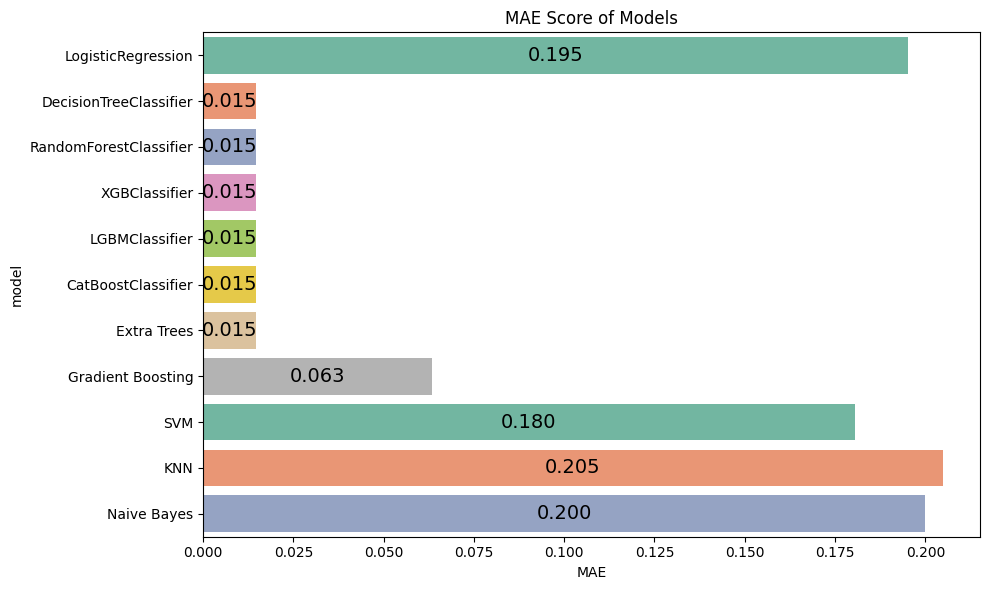

C:\Users\Palak\AppData\Local\Temp\ipykernel_17100\1381055289.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(data=df_score,x=col,y="model",palette="Set2")


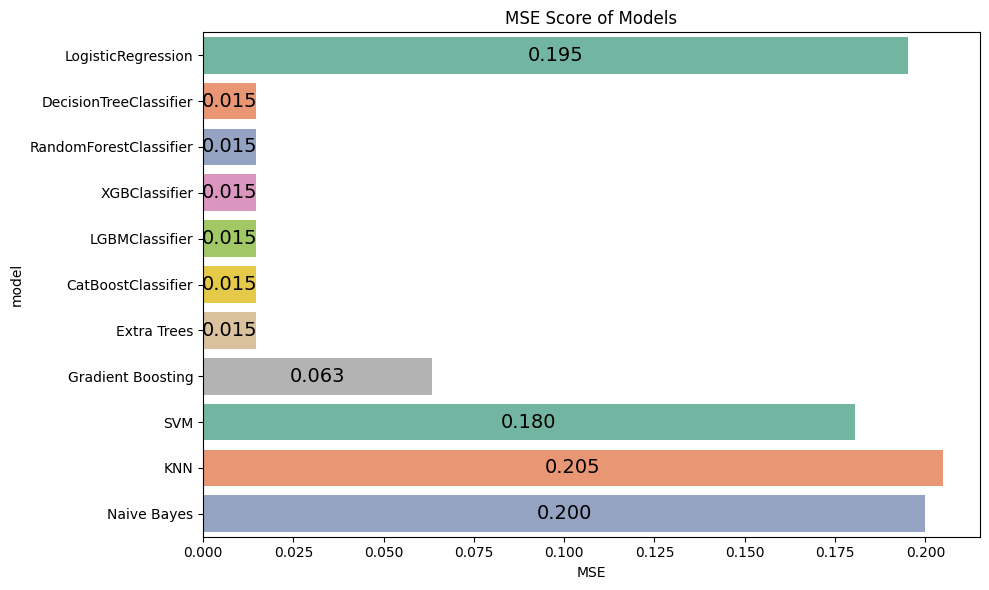

C:\Users\Palak\AppData\Local\Temp\ipykernel_17100\1381055289.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(data=df_score,x=col,y="model",palette="Set2")


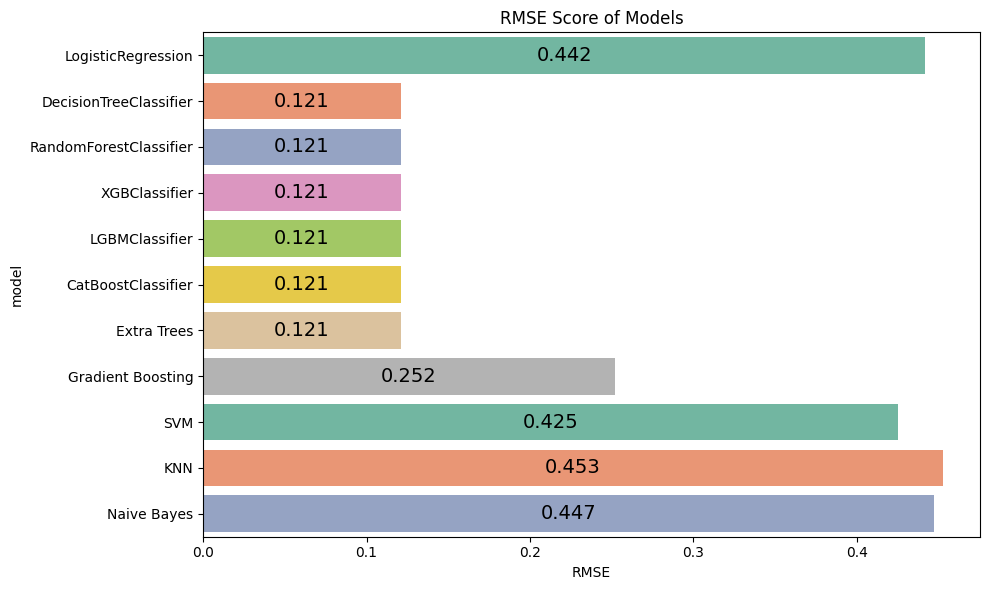

C:\Users\Palak\AppData\Local\Temp\ipykernel_17100\1381055289.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(data=df_score,x=col,y="model",palette="Set2")


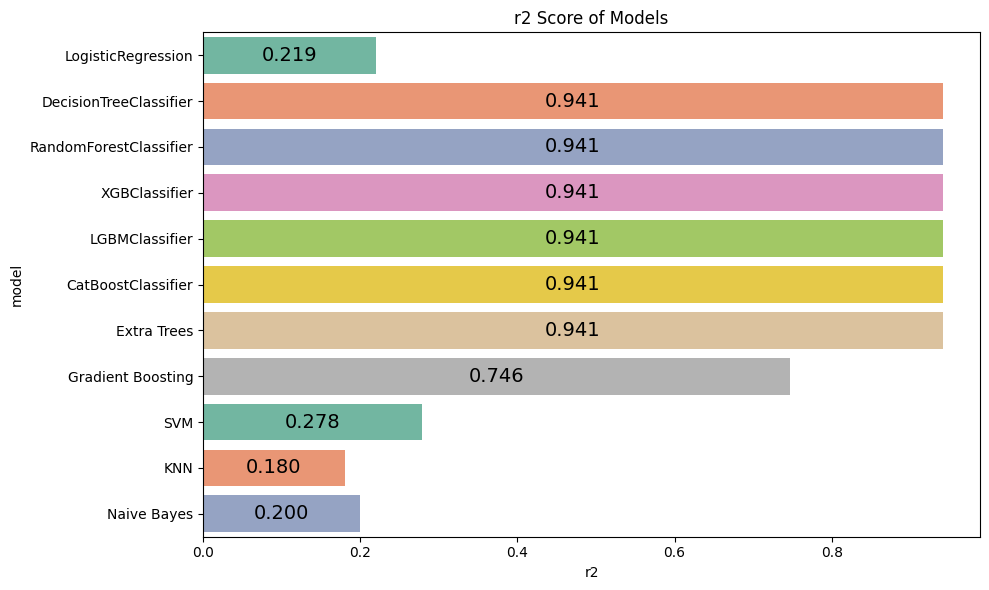

In [35]:
for col in df_score.columns[1::]:
    plt.figure(figsize=(10,6))
    ax=sns.barplot(data=df_score,x=col,y="model",palette="Set2")
    for c in ax.containers:
        ax.bar_label(c,fmt="{:1.3f}",fontsize=14,label_type="center")
    plt.title(f"{col} Score of Models")
    plt.tight_layout()
    plt.show()

In [36]:
""" #Hyper Parameter Optimization
#six model have been chosen for hyperparameter tuning. These are:
LGBM
XGB
CatBoost
Random Forest
decision tree
extra tree
"""

' #Hyper Parameter Optimization\n#six model have been chosen for hyperparameter tuning. These are:\nLGBM\nXGB\nCatBoost\nRandom Forest\ndecision tree\nextra tree\n'

In [44]:
def base_model(x,y,scoring="accuracy"):
    models=[("DecisionTree", DecisionTreeClassifier(random_state=42)),
        ("RandomForest", RandomForestClassifier(random_state=42)),
        ("XGB", XGBClassifier(eval_metric='logloss', random_state=42)),
        ("LGBM", LGBMClassifier(random_state=42)),
        ("CatBoost", CatBoostClassifier(verbose=0, random_state=42)),
        ("ExtraTrees", ExtraTreesClassifier(random_state=42))]
    for name, classification in models:
        cv_result= cross_validate(classification,x,y,cv=5,scoring=scoring)
        print(f"Accuracy: {round(cv_result['test_score'].mean()*100, 2)}% ({name})")

        

In [45]:
DecisionTree_prams= {"max_depth": [3, 5, 7, 9],
               "min_samples_split": [2, 5, 10]
}
RandomForest_prams= {
        "n_estimators": [200, 300],
        "max_depth": [8, 15, None],
        "min_samples_split": [2, 5]
}
Xgb_prams={
    "learning_rate": [0.1, 0.01],
    "max_depth": [5, 8],
    "n_estimators": [100, 200],
    "colsample_bytree": [0.5, 1]
}
lgbm_params = {"learning_rate": [0.01, 0.1],
               "n_estimators": [300, 500, 1500],
               "colsample_bytree": [0.5, 0.7, 1]}
catBoost_prams={
    "iterations": [100, 500, 1000],
    "learning_rate": [0.01, 0.1, 0.2],
    "depth": [5, 7, 9]
}
ExtraTree_prams={
    "n_estimators": [200, 300],
    "max_depth": [8, 15, None],
    "min_samples_split": [2, 5]
}

In [46]:
models = [
    ("DecisionTree", DecisionTreeClassifier(random_state=42), DecisionTree_prams),
    ("RandomForest", RandomForestClassifier(random_state=42), RandomForest_prams),
    ("XGB", XGBClassifier(eval_metric='logloss', random_state=42), Xgb_prams),
    ("LGBM", LGBMClassifier(random_state=42), lgbm_params),
    ("CatBoost", CatBoostClassifier(verbose=0, random_state=42), catBoost_prams),
    ("ExtraTrees", ExtraTreesClassifier(random_state=42), ExtraTree_prams)
]


In [47]:
def hyperparameter_optimization(x,y,cv=5,scoring="accuracy"):
    print("hyperparameter optimization.....")
    best_model={}
    for name, classification,params in models:
        print(f"........{name}....")
        # before tunning 
        cv_results = cross_validate(classification, x, y, cv=cv, scoring=scoring)
        print(f"{scoring}(Before): {round(cv_results['test_score'].mean(),4)}")
        
        gs=GridSearchCV(classification,params,cv=cv,n_jobs=-1,verbose=False)
        gs.fit(x,y)
        final_model = gs.best_estimator_
        # after tunning 
        cv_results_after=cross_validate(final_model,x,y,cv=cv,scoring=scoring)
        print(f"{scoring}(After): {round(cv_results_after['test_score'].mean(),4)}")
        print(f"{name} best params: {gs.best_params_}\n")
        best_model[name]=final_model
    return best_model

In [48]:
def fit_model(x,y):
    base_model(x,y)
    best_models=hyperparameter_optimization(x,y)
    return best_models

best_models =fit_model(x_train,y_train)

Accuracy: 97.56% (DecisionTree)
Accuracy: 98.17% (RandomForest)
Accuracy: 98.05% (XGB)
Accuracy: 98.17% (LGBM)
Accuracy: 97.8% (CatBoost)
Accuracy: 98.41% (ExtraTrees)
hyperparameter optimization.....
........DecisionTree....
accuracy(Before): 0.9756
accuracy(After): 0.9756
DecisionTree best params: {'max_depth': 9, 'min_samples_split': 2}

........RandomForest....
accuracy(Before): 0.9817
accuracy(After): 0.9817
RandomForest best params: {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 200}

........XGB....
accuracy(Before): 0.9805
accuracy(After): 0.9817
XGB best params: {'colsample_bytree': 0.5, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}

........LGBM....
accuracy(Before): 0.9817
accuracy(After): 0.9817
LGBM best params: {'colsample_bytree': 0.5, 'learning_rate': 0.1, 'n_estimators': 300}

........CatBoost....
accuracy(Before): 0.978
accuracy(After): 0.9817
CatBoost best params: {'depth': 7, 'iterations': 500, 'learning_rate': 0.1}

........ExtraTrees....
ac

In [50]:
final_model= best_models["ExtraTrees"].fit(x_train,y_train)

In [54]:
permutation= PermutationImportance(final_model,random_state=42,n_iter=10).fit(x_test,y_test)
#display(eli5.show_weights(permutation, feature_names=x_test.columns.tolist()))
# Just change text color to black
display(HTML('<style>table.eli5-weights td, table.eli5-weights th {color: black;}</style>'))
display(eli5.show_weights(permutation, feature_names=x_test.columns.tolist()))


Weight,Feature
0.0473 ± 0.0283,cp
0.0376 ± 0.0158,ca
0.0361 ± 0.0152,thal
0.0356 ± 0.0138,sex
0.0298 ± 0.0092,exang
0.0151 ± 0.0111,restecg
0.0127 ± 0.0089,slope
0.0000 ± 0.0115,oldpeak
0.0000 ± 0.0115,thalach
0 ± 0.0000,fbs


In [57]:
def plot_importance(model, type, features=None, x_test=None, y_test=None, save=False):
    if type == 'feature_importance':
        df_imp = pd.DataFrame({'Value': model.feature_importances_, 
                               'Feature': features.columns})
        
        plt.figure(figsize=(15, 6))
        sns.set_theme(font_scale=1)
        ax = sns.barplot(x="Feature", y="Value", 
                         data=df_imp.sort_values(by="Value", ascending=False),
                         palette='Set3')

        for container in ax.containers:
            ax.bar_label(container,  fmt="{:1.2f}", fontsize=12)
        plt.title('Feature Importance')
        plt.xticks(rotation=30)
        plt.tight_layout()
        if save:
            plt.savefig("feature_importance.png")
        plt.show()
        
    elif type == 'permutation_importance' and features is None:
        model_copy = model
        perm = PermutationImportance(model, random_state=42, n_iter=10).fit(x_test, y_test)
        df_imp = pd.DataFrame({'Feature': x_test.columns.tolist(),
                               'Value': perm.feature_importances_, 
                               'Std': perm.feature_importances_std_,})
        
        plt.figure(figsize=(10, 6))
        sns.set_theme(font_scale=1)
        ax = sns.barplot(x="Feature", y="Value", 
                         data=df_imp.sort_values(by="Value", ascending=False),
                         palette='Set3')

        for container in ax.containers:
            ax.bar_label(container,  fmt="{:1.4f}", fontsize=11)
        plt.title('Permutation Importance (test set)')
        plt.xticks(rotation=30)
        plt.tight_layout()
        if save:
            plt.savefig("permutation_importance.png")
        plt.show()
        
    else:
        return f'Unsupported importance type.'

C:\Users\Palak\AppData\Local\Temp\ipykernel_17100\1253948526.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x="Feature", y="Value",


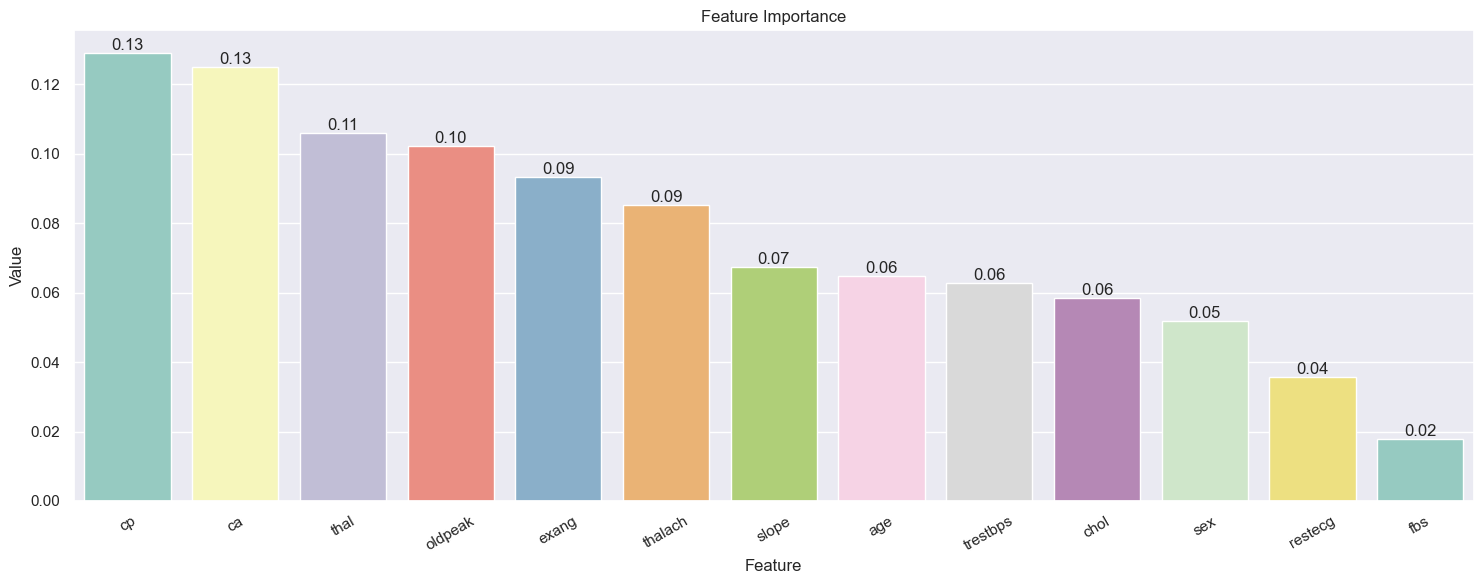

In [58]:
plot_importance(final_model, 'feature_importance', x)

C:\Users\Palak\AppData\Local\Temp\ipykernel_17100\1253948526.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x="Feature", y="Value",


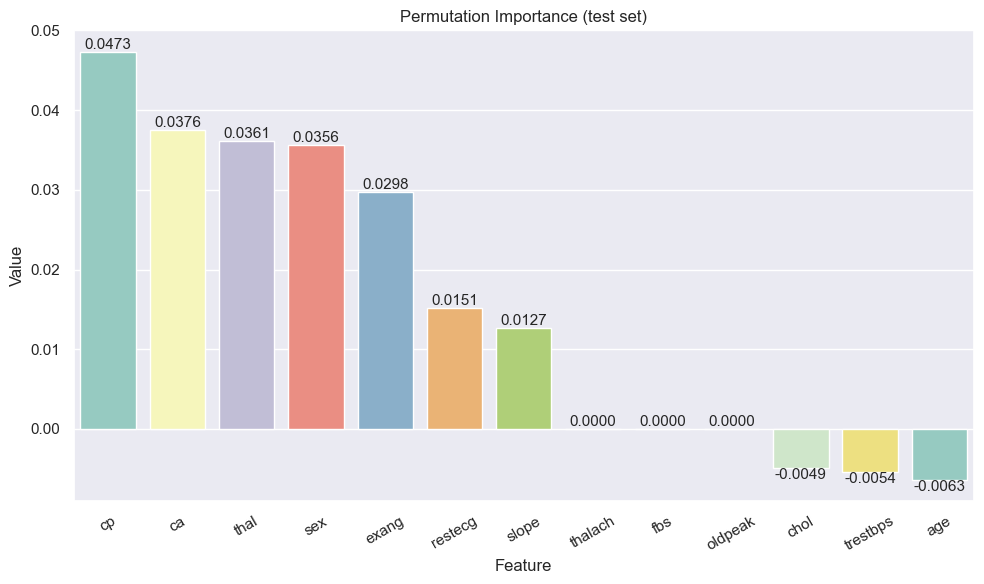

In [59]:
plot_importance(final_model, type='permutation_importance', x_test=x_test, y_test=y_test)

In [63]:
y_pred = final_model.predict(x_test)
y_prob = final_model.predict_proba(x_test)[:, 1]
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.99       102
           1       1.00      0.97      0.99       103

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205



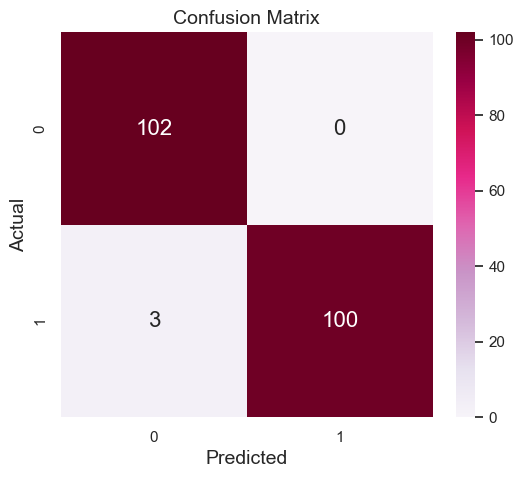

In [64]:
# confussion matrix
cnf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="PuRd", fmt='d', annot_kws={"size": 16})
plt.title('Confusion Matrix', size=14)
plt.ylabel('Actual', size=14)
plt.xlabel('Predicted', size=14)
plt.show()


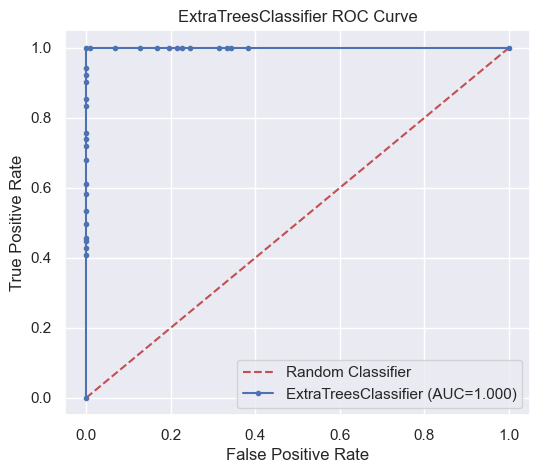

In [65]:
auc_score = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,5))
plt.plot([0,1],[0,1],'r--', label='Random Classifier')
plt.plot(fpr, tpr, marker='.', label=f'{final_model.__class__.__name__} (AUC={auc_score:.3f})')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'{final_model.__class__.__name__} ROC Curve')
plt.legend()
plt.show()

In [68]:
scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score),
    'recall': make_scorer(recall_score),
    'f1': make_scorer(f1_score),
    'roc_auc': 'roc_auc'
}

cv_results = cross_validate(final_model, x, y, cv=5, scoring=scoring)

print("Cross-validated Metrics (5-Fold):\n")
for metric in scoring.keys():
    mean_score = cv_results[f'test_{metric}'].mean()
    std_score = cv_results[f'test_{metric}'].std()
    print(f"{metric.capitalize():<10}: {mean_score:.4f} (+/- {std_score:.4f})")

Cross-validated Metrics (5-Fold):

Accuracy  : 0.9971 (+/- 0.0059)
Precision : 0.9945 (+/- 0.0110)
Recall    : 1.0000 (+/- 0.0000)
F1        : 0.9972 (+/- 0.0056)
Roc_auc   : 1.0000 (+/- 0.0000)


In [71]:
final_model.fit(x, y)
joblib.dump(final_model, 'final_model_catboost.pkl')

['final_model_catboost.pkl']